# 3. Calibration of the trained networks

Simulation-based calibration: for simulations drawn from the prior, check how often the true parameter
lies inside the posterior credible interval. For a calibrated network, the fraction of true values inside
the X% interval is X%, i.e. the coverage curve follows the diagonal. The README figure uses 300 simulations;
here 100 to keep it quick.

In [1]:
%matplotlib inline
import os, warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy import stats
from GWBackFinder import Simulator
from GWBackFinder.prior import get_prior
from GWBackFinder.posterior import load_posterior, _flow_sample_in_box

N, S = 100, 500          # simulations, posterior samples per simulation
posterior_AA = load_posterior("AA_channel/posterior_AA.pkl")
posterior_TT = load_posterior("TT_channel/posterior_TT.pkl")
sim = Simulator()
torch.manual_seed(0)

In [2]:
# AA: data with the true P appended, as in training
thetas_AA = get_prior().sample((N,))
X_AA = torch.tensor(sim.simulate_AA_batch(thetas_AA.numpy(), seed=0, n_jobs=os.cpu_count()))
ranks = np.zeros((N, 28))
for i in range(N):
    s, keep = _flow_sample_in_box(posterior_AA, X_AA[i].expand(S, -1), n_dims_box=27)
    ranks[i] = (s[keep].numpy() < thetas_AA[i].numpy()).mean(0)

# TT
P = np.random.default_rng(1).normal(15, 3, (N, 1))
X_TT = torch.tensor(sim.simulate_TT_batch(P, seed=1, n_jobs=os.cpu_count()))
ranks_TT = np.array([(posterior_TT.sample((S,), x=X_TT[i], show_progress_bars=False).numpy().ravel() < P[i, 0]).mean()
                     for i in range(N)])

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:04<00:00, 22.04it/s]

100%|██████████| 100/100 [00:04<00:00, 21.84it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:00<00:00, 177.86it/s]

100%|██████████| 100/100 [00:00<00:00, 135.54it/s]

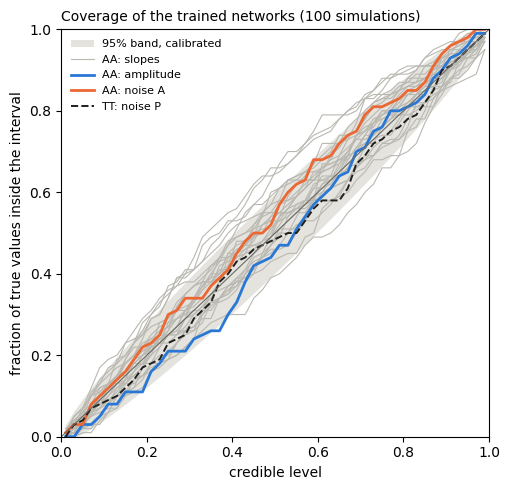

In [3]:
lv = np.linspace(0.01, 0.99, 50)
band = 1.96 * np.sqrt(lv * (1 - lv) / N)
cov = lambda r: [((r > (1 - l) / 2) & (r < (1 + l) / 2)).mean() for l in lv]   # central-interval coverage

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.fill_between(lv, lv - band, lv + band, color="#e4e3de", lw=0, label="95% band, calibrated")
for j in range(26):
    ax.plot(lv, cov(ranks[:, j]), color="#b9b8b1", lw=0.8, label="AA: slopes" if j == 0 else None)
ax.plot(lv, cov(ranks[:, 26]), color="#2a78d6", lw=2, label="AA: amplitude")
ax.plot(lv, cov(ranks[:, 27]), color="#eb6834", lw=2, label="AA: noise A")
ax.plot(lv, cov(ranks_TT), color="#1f1f1e", lw=1.4, ls="--", label="TT: noise P")
ax.plot([0, 1], [0, 1], color="#6b6a64", lw=0.8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("credible level"); ax.set_ylabel("fraction of true values inside the interval")
ax.set_title(f"Coverage of the trained networks ({N} simulations)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left"); fig.tight_layout()